# Entrega 02 – Análise de Regressão

**Análise Inferencial – Projeto Interdisciplinar 4º semestre CCOMP – FECAP / CTI Global**

Professor: Rodinil da Silva Moreira Lisboa

Integrantes: Bruno Nobrega, Kaio Inglez, Mauricio Suster e Yuri Santana

Na Entrega 01 fizemos a análise descritiva. Agora vamos ajustar modelos de **regressão linear** para entender o que explica a diferença de **lucro líquido** entre os cenários simulados pela CTI. Vamos interpretar os coeficientes, ver a qualidade do ajuste (R², RMSE), fazer os diagnósticos dos resíduos e anotar as limitações.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor

## 1. Leitura dos dados

Mesmo arquivo da Entrega 01 (`Demonstrativo Fecap v3.csv`, dentro do `DADOS_FECAP.zip`). No Google Colab a célula abaixo pede para enviar o zip.

In [2]:
import os, zipfile

if not os.path.exists('Demonstrativo Fecap v3.csv'):
    from google.colab import files      # só funciona no Colab
    enviados = files.upload()           # enviar o DADOS_FECAP.zip (ou o próprio CSV)
    for nome in enviados:
        if nome.lower().endswith('.zip'):
            zipfile.ZipFile(nome).extractall()

dados = pd.read_csv('Demonstrativo Fecap v3.csv', sep=';', encoding='latin1', header=None,
                    names=['ano', 'cenario', 'conta', 'valor'])
dados = dados.dropna(subset=['conta'])
dados['conta'] = dados['conta'].str.replace(r'\s+', ' ', regex=True).str.strip()   # tira espaços duplicados
dados['valor'] = dados['valor'].str.replace('.', '', regex=False).str.replace(',', '.', regex=False).astype(float)
dados['ano'] = dados['ano'].str.replace('Ano ', '').astype(int)
dados['cenario'] = dados['cenario'].str.replace('Total Cen_', '').astype(int)
print('Linhas:', len(dados), '| anos:', dados['ano'].nunique(), '| cenários:', dados['cenario'].nunique())

Linhas: 958800 | anos: 12 | cenários: 1200


## 2. Montando a base para a regressão

Usamos 3 contas da DRE (em **R\$ milhões**):

| Variável | Como calculamos | Papel no modelo |
|---|---|---|
| `lucro` | DRE - Resultado Líquido | variável resposta (y) |
| `receita_liq` | DRE - Receita + DRE - Tributos (tributos vêm negativos) | explicativa |
| `custos` | DRE - Custos × (-1) | explicativa |
| `grupo2` | 1 se o cenário é de 1001 a 1200, 0 se é de 1 a 1000 | explicativa (dummy) |

Na Entrega 01 vimos que os cenários 1001 a 1200 se comportam diferente, por isso criamos a dummy `grupo2`.

Para não misturar o efeito do tempo (a receita cresce ano a ano), a análise principal é feita **dentro de um ano só: o Ano 6**, com os 1.200 cenários (n = 1.200). Escolhemos o Ano 6 por ser o meio da concessão. Depois repetimos o modelo para todos os anos.

In [3]:
contas = {'DRE - Resultado Líquido': 'lucro', 'DRE - Receita': 'receita', 'DRE - Tributos': 'tributos', 'DRE - Custos': 'custos'}
base = dados[dados['conta'].isin(contas)].pivot_table(index=['cenario', 'ano'], columns='conta', values='valor').rename(columns=contas)
base = base / 1e6                                         # R$ milhões
base['receita_liq'] = base['receita'] + base['tributos']
base['custos'] = -base['custos']
base = base.reset_index()
base['grupo2'] = (base['cenario'] > 1000).astype(int)

ano6 = base[base['ano'] == 6].copy()
print('Observações no Ano 6:', len(ano6))
ano6[['lucro', 'receita_liq', 'custos']].describe().round(1)

Observações no Ano 6: 1200


conta,lucro,receita_liq,custos
count,1200.0,1200.0,1200.0
mean,2950.9,6624.4,1110.5
std,71.0,103.9,19.6
min,2353.9,5776.6,1024.0
25%,2956.8,6613.7,1097.5
50%,2961.1,6621.3,1106.5
75%,2965.6,6634.8,1124.4
max,3476.3,7549.3,1160.5


Correlação (Ano 6):
conta        lucro  receita_liq  custos  grupo2
conta                                          
lucro         1.00         0.92    0.27   -0.38
receita_liq   0.92         1.00    0.34   -0.04
custos        0.27         0.34    1.00   -0.26
grupo2       -0.38        -0.04   -0.26    1.00


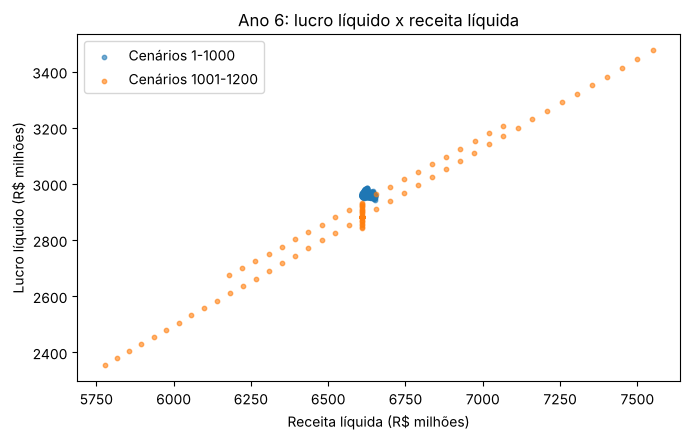

In [4]:
print('Correlação (Ano 6):')
print(ano6[['lucro', 'receita_liq', 'custos', 'grupo2']].corr().round(2))

fig, ax = plt.subplots(figsize=(7, 4.5))
for g, cor, nome in [(0, 'tab:blue', 'Cenários 1-1000'), (1, 'tab:orange', 'Cenários 1001-1200')]:
    d = ano6[ano6['grupo2'] == g]
    ax.scatter(d['receita_liq'], d['lucro'], s=10, alpha=0.6, color=cor, label=nome)
ax.set_xlabel('Receita líquida (R$ milhões)')
ax.set_ylabel('Lucro líquido (R$ milhões)')
ax.set_title('Ano 6: lucro líquido x receita líquida')
ax.legend()
plt.tight_layout()
plt.savefig('fig1_dispersao.png', dpi=150)
plt.show()

**O que vimos:** o lucro tem correlação forte com a receita líquida (0,92), fraca com os custos (0,27) e negativa com o grupo 1001-1200 (-0,38). No gráfico, os cenários 1 a 1000 (azul) ficam todos juntos num ponto pequeno, enquanto os cenários 1001 a 1200 (laranja) se espalham ao longo de duas retas quase paralelas, e 140 deles formam uma coluna com a mesma receita. É nesse grupo que a receita mais varia. Por isso faz sentido testar uma regressão do lucro pela receita.

## 3. Modelo 1 – Regressão linear simples

$$\text{lucro} = \beta_0 + \beta_1 \cdot \text{receita\_liq} + \varepsilon$$

In [5]:
m1 = smf.ols('lucro ~ receita_liq', data=ano6).fit()
print(m1.summary().tables[1])
print(f'R² = {m1.rsquared:.4f} | R² ajustado = {m1.rsquared_adj:.4f} | RMSE = {np.sqrt(m1.mse_resid):.2f} | n = {int(m1.nobs)}')
print('Intervalo de confiança 95% da inclinação:', m1.conf_int().loc['receita_liq'].round(4).tolist())

                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept   -1228.8442     49.966    -24.593      0.000   -1326.876   -1130.813
receita_liq     0.6310      0.008     83.661      0.000       0.616       0.646
R² = 0.8539 | R² ajustado = 0.8537 | RMSE = 27.14 | n = 1200
Intervalo de confiança 95% da inclinação: [0.6162, 0.6458]


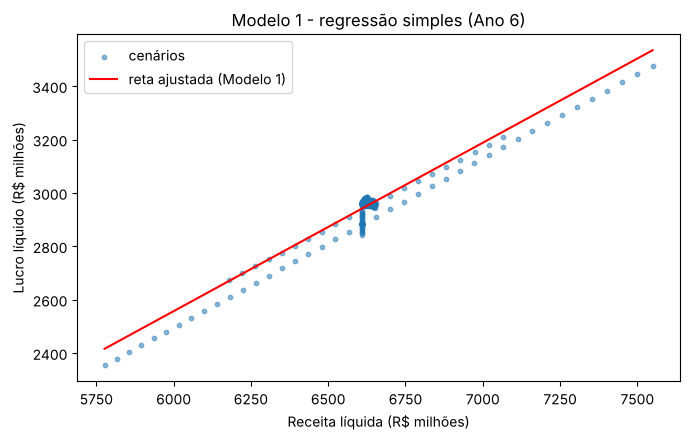

In [6]:
x = np.linspace(ano6['receita_liq'].min(), ano6['receita_liq'].max(), 50)
plt.figure(figsize=(7, 4.5))
plt.scatter(ano6['receita_liq'], ano6['lucro'], s=10, alpha=0.5, label='cenários')
plt.plot(x, m1.params['Intercept'] + m1.params['receita_liq'] * x, color='red', label='reta ajustada (Modelo 1)')
plt.xlabel('Receita líquida (R$ milhões)')
plt.ylabel('Lucro líquido (R$ milhões)')
plt.title('Modelo 1 - regressão simples (Ano 6)')
plt.legend()
plt.tight_layout()
plt.show()

**Interpretação do Modelo 1**

- **Inclinação (β1 = 0,631):** cada R\$ 1 milhão a mais de receita líquida está associado, em média, a **R\$ 0,63 milhão a mais de lucro líquido**. O intervalo de confiança de 95% vai de 0,616 a 0,646 e o p-valor é praticamente zero, então o efeito é significativo.
- **Intercepto (β0 = -1.228,8):** não tem interpretação prática (seria o lucro com receita zero, valor muito fora dos dados). Ele só posiciona a reta.
- **R² = 0,854:** a receita sozinha explica cerca de 85% da variação do lucro entre os cenários do Ano 6. O erro típico (RMSE) é de R\$ 27,1 milhões, o que é menos de 1% do lucro médio (R\$ 2.950,9 milhões).
- Pelo gráfico, a reta segue os cenários laranja que variam a receita, mas os cenários 1-1000 ficam um pouco acima dela (R\$ 10,5 milhões, em média) e 140 cenários do grupo 1001-1200 têm a mesma receita (R\$ 6.610,9 milhões) com lucros diferentes (de R\$ 2.843 a 2.932 milhões). Então só a receita não explica tudo: falta variável no modelo → Modelo 2.

## 4. Modelo 2 – Regressão linear múltipla

$$\text{lucro} = \beta_0 + \beta_1 \cdot \text{receita\_liq} + \beta_2 \cdot \text{custos} + \beta_3 \cdot \text{grupo2} + \varepsilon$$

In [7]:
m2 = smf.ols('lucro ~ receita_liq + custos + grupo2', data=ano6).fit()
print(m2.summary().tables[1])
print(f'R² = {m2.rsquared:.4f} | R² ajustado = {m2.rsquared_adj:.4f} | RMSE = {np.sqrt(m2.mse_resid):.2f}')
print(f'Teste F: F = {m2.fvalue:.1f}, p-valor = {m2.f_pvalue:.3g}')

# multicolinearidade (VIF): acima de 5 ou 10 seria problema
X = m2.model.exog
for i, nome in enumerate(m2.model.exog_names):
    if nome != 'Intercept':
        print(f'VIF {nome}: {variance_inflation_factor(X, i):.2f}')

                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept    -773.2183     16.062    -48.139      0.000    -804.731    -741.705
receita_liq     0.6549      0.002    299.498      0.000       0.651       0.659
custos         -0.5423      0.012    -45.129      0.000      -0.566      -0.519
grupo2        -72.1293      0.594   -121.339      0.000     -73.296     -70.963
R² = 0.9891 | R² ajustado = 0.9891 | RMSE = 7.40
Teste F: F = 36344.0, p-valor = 0
VIF receita_liq: 1.13
VIF custos: 1.21
VIF grupo2: 1.08


**Interpretação do Modelo 2** (cada coeficiente vale "mantendo as outras variáveis constantes")

- **Receita líquida (β1 = 0,655):** R\$ 1 milhão a mais de receita → **+R\$ 0,655 milhão de lucro**. Esse valor é quase igual a 1 - 34% = 0,66, ou seja, o que sobra da receita depois do IR e da CSLL (no Ano 6 a alíquota efetiva é 34,4%). O modelo "achou" a alíquota de imposto da empresa.
- **Custos (β2 = -0,542):** R\$ 1 milhão a mais de custos → **-R\$ 0,54 milhão de lucro**. O sinal é o esperado (custo reduz lucro). O valor é um pouco menor que 0,66 em módulo, provavelmente porque outras contas que não estão no modelo andam junto com os custos.
- **Grupo 1001-1200 (β3 = -72,1):** com a mesma receita e os mesmos custos, um cenário desse grupo tem, em média, **R\$ 72 milhões a menos de lucro**. Conferindo nos dados, esse grupo tem depreciação maior (R\$ 920 contra R\$ 846 milhões) e resultado financeiro pior (-R\$ 237 contra -R\$ 200 milhões). Essas duas diferenças, já descontado o imposto, dão cerca de R\$ 74 milhões, bem perto do coeficiente.
- **Qualidade do ajuste:** R² = 0,989 e R² ajustado = 0,989 (subiu de 0,854 para 0,989). O RMSE caiu de R\$ 27,1 para R\$ 7,4 milhões. O teste F (p ≈ 0) mostra que o modelo como um todo é significativo.
- **Multicolinearidade:** todos os VIF ficaram perto de 1 (máximo 1,21), então as variáveis explicativas não estão repetindo informação.

## 5. Diagnóstico dos resíduos (Modelo 2)

Pressupostos da regressão linear que vamos olhar:
- **Homocedasticidade** (variância constante dos resíduos) → gráfico resíduo x ajustado e teste de **Breusch-Pagan** (H0: variância constante).
- **Normalidade dos resíduos** → histograma, gráfico QQ e teste de **Jarque-Bera** (H0: resíduos normais).
- **Multicolinearidade** → VIF (já calculado acima).

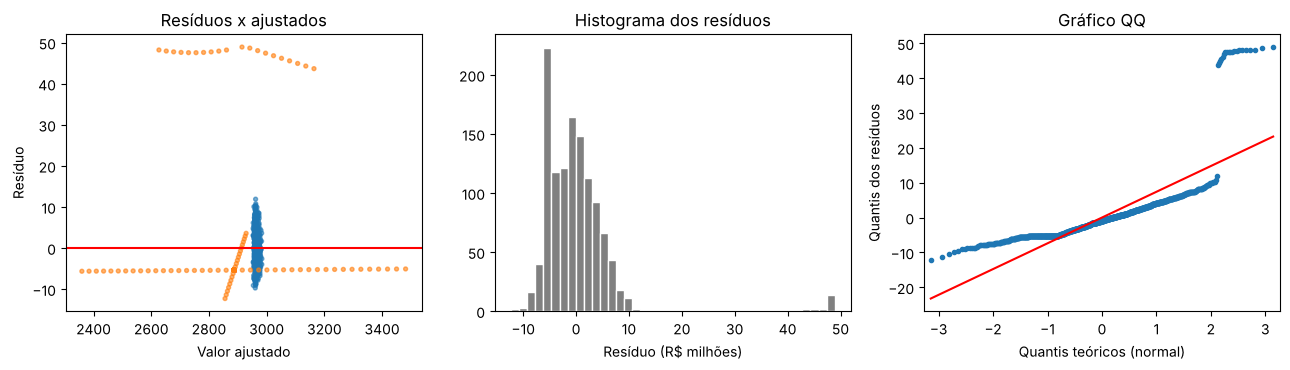

Breusch-Pagan: estatística = 114.2, p-valor = 1.38e-24
Jarque-Bera: estatística = 34823.5, p-valor = 0, assimetria = 4.29, curtose = 27.95
Desvio padrão do resíduo por grupo: {0: 3.95, 1: 15.83}
Cenários com resíduo acima de R$ 40 milhões: 20 -> todos do grupo 1001-1200? True


In [8]:
res = m2.resid
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
cores = np.where(ano6['grupo2'] == 1, 'tab:orange', 'tab:blue')
ax[0].scatter(m2.fittedvalues, res, s=8, alpha=0.6, c=cores)
ax[0].axhline(0, color='red')
ax[0].set_xlabel('Valor ajustado'); ax[0].set_ylabel('Resíduo'); ax[0].set_title('Resíduos x ajustados')
ax[1].hist(res, bins=40, color='gray', edgecolor='white')
ax[1].set_title('Histograma dos resíduos'); ax[1].set_xlabel('Resíduo (R$ milhões)')
sm.qqplot(res, line='s', ax=ax[2], markersize=3)
ax[2].set_title('Gráfico QQ'); ax[2].set_xlabel('Quantis teóricos (normal)'); ax[2].set_ylabel('Quantis dos resíduos')
plt.tight_layout()
plt.savefig('fig2_residuos.png', dpi=150)
plt.show()

bp = het_breuschpagan(res, m2.model.exog)
jb = jarque_bera(res)
print(f'Breusch-Pagan: estatística = {bp[0]:.1f}, p-valor = {bp[1]:.3g}')
print(f'Jarque-Bera: estatística = {jb[0]:.1f}, p-valor = {jb[1]:.3g}, assimetria = {jb[2]:.2f}, curtose = {jb[3]:.2f}')
print('Desvio padrão do resíduo por grupo:', res.groupby(ano6['grupo2']).std().round(2).to_dict())
print('Cenários com resíduo acima de R$ 40 milhões:', (res > 40).sum(), '-> todos do grupo 1001-1200?', bool(ano6.loc[res > 40, 'grupo2'].all()))

Como os testes rejeitaram homocedasticidade e normalidade, refazemos o Modelo 2 com **erros-padrão robustos (HC3)**. Os coeficientes não mudam, só os erros-padrão e os p-valores.

In [9]:
m2r = smf.ols('lucro ~ receita_liq + custos + grupo2', data=ano6).fit(cov_type='HC3')
comp = pd.DataFrame({'coef': m2.params, 'ep_comum': m2.bse, 'ep_robusto_HC3': m2r.bse, 'p_robusto': m2r.pvalues})
print(comp.round(4))
print('IC 95% robusto:')
print(m2r.conf_int().round(4))

                 coef  ep_comum  ep_robusto_HC3  p_robusto
Intercept   -773.2183   16.0621         34.4261        0.0
receita_liq    0.6549    0.0022          0.0045        0.0
custos        -0.5423    0.0120          0.0083        0.0
grupo2       -72.1293    0.5944          1.1542        0.0
IC 95% robusto:
                    0         1
Intercept   -840.6922 -705.7445
receita_liq    0.6461    0.6637
custos        -0.5586   -0.5259
grupo2       -74.3916  -69.8670


**Resultado do diagnóstico**

- **Homocedasticidade:** o teste de Breusch-Pagan deu p-valor ≈ 0, então **rejeitamos** a variância constante. O gráfico mostra o motivo: os resíduos do grupo 1001-1200 (laranja) são bem mais espalhados (desvio padrão de 15,8 contra 4,0 no grupo 1-1000).
- **Normalidade:** o teste de Jarque-Bera também **rejeitou** a normalidade (assimetria 4,3 e curtose 28). O histograma e o gráfico QQ mostram uma cauda longa à direita: 20 cenários seguidos (1069 a 1088), todos do grupo 1001-1200, têm lucro cerca de R\$ 43 a 49 milhões acima do previsto. Nesses cenários variam contas que não estão no modelo (depreciação e resultado financeiro).
- No gráfico de resíduos, os pontos laranja formam "linhas". Parece que os cenários 1001-1200 foram gerados mudando uma variável de cada vez (como uma análise de sensibilidade), o que também explica por que esse grupo é diferente.
- **O que fizemos:** como temos 1.200 observações, as estimativas dos coeficientes continuam boas, mas os erros-padrão comuns não são confiáveis. Com os **erros-padrão robustos HC3**, os erros-padrão mudaram (da receita foi de 0,0022 para 0,0045), mas todos os coeficientes continuam significativos (p < 0,001) e os intervalos de confiança continuam estreitos. A conclusão não muda.

## 6. Comparação dos modelos e validação treino/teste

Separamos 80% dos cenários para ajustar o modelo (treino) e 20% para testar (teste), para ver se o modelo funciona em dados que ele não viu.

In [10]:
def metricas(m):
    return {'R²': m.rsquared, 'R² ajustado': m.rsquared_adj, 'AIC': m.aic, 'RMSE': np.sqrt(m.mse_resid)}
print(pd.DataFrame({'Modelo 1 (simples)': metricas(m1), 'Modelo 2 (múltiplo)': metricas(m2)}).round(3))

teste_df = ano6.sample(frac=0.2, random_state=42)     # 20% para teste
treino_df = ano6.drop(teste_df.index)                  # 80% para treino
for nome, formula in [('Modelo 1', 'lucro ~ receita_liq'), ('Modelo 2', 'lucro ~ receita_liq + custos + grupo2')]:
    m = smf.ols(formula, data=treino_df).fit()
    prev = m.predict(teste_df)
    erro = teste_df['lucro'] - prev
    r2_teste = 1 - (erro ** 2).sum() / ((teste_df['lucro'] - teste_df['lucro'].mean()) ** 2).sum()
    print(f'{nome}: treino n={len(treino_df)}, teste n={len(teste_df)} | R² no teste = {r2_teste:.4f} | RMSE no teste = {np.sqrt((erro ** 2).mean()):.2f} | MAE = {erro.abs().mean():.2f}')

             Modelo 1 (simples)  Modelo 2 (múltiplo)
R²                        0.854                0.989
R² ajustado               0.854                0.989
AIC                   11329.513             8212.989
RMSE                     27.136                7.400
Modelo 1: treino n=960, teste n=240 | R² no teste = 0.7477 | RMSE no teste = 26.62 | MAE = 19.44
Modelo 2: treino n=960, teste n=240 | R² no teste = 0.9865 | RMSE no teste = 6.15 | MAE = 3.93


**Comparação:** o Modelo 2 é melhor em todas as métricas: R² maior, AIC menor e RMSE quase 4 vezes menor. Na validação, o Modelo 2 manteve o desempenho nos 240 cenários de teste (R² e erro parecidos com os do treino), então ele não está "decorando" os dados. O Modelo 1 piorou mais no teste, porque depende de poucos cenários extremos do grupo 1001-1200.

## 7. O modelo vale para os outros anos?

Repetimos o Modelo 2 para cada um dos 12 anos (1.200 cenários em cada).

        R²  coef_receita  coef_custos  coef_grupo2  p_custos    RMSE
ano                                                                 
1    0.937         0.618       -0.575      -94.228     0.000  11.407
2    0.966         0.622        0.450     -126.677     0.000  10.657
3    0.973         0.627        0.012     -109.134     0.640   8.429
4    0.976         0.623        0.061     -150.695     0.009  10.794
5    0.986         0.640       -0.252     -116.741     0.000   8.130
6    0.989         0.655       -0.542      -72.129     0.000   7.400
7    0.992         0.657       -0.594      -71.514     0.000   7.400
8    0.995         0.657       -0.583      -81.289     0.000   7.511
9    0.994         0.651       -0.441     -134.547     0.000   9.699
10   0.995         0.646       -0.300     -162.938     0.000  11.309
11   0.995         0.644       -0.140     -174.282     0.000  12.934
12   0.994         0.644        0.020     -210.751     0.281  17.479


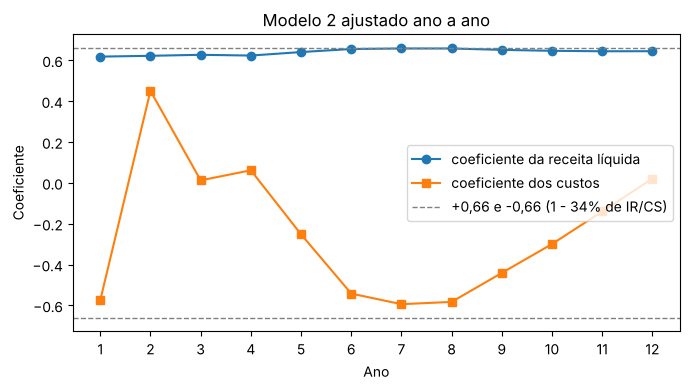

In [11]:
linhas = []
for a in range(1, 13):
    m = smf.ols('lucro ~ receita_liq + custos + grupo2', data=base[base['ano'] == a]).fit()
    linhas.append({'ano': a, 'R²': m.rsquared, 'coef_receita': m.params['receita_liq'], 'coef_custos': m.params['custos'],
                   'coef_grupo2': m.params['grupo2'], 'p_custos': m.pvalues['custos'], 'RMSE': np.sqrt(m.mse_resid)})
por_ano = pd.DataFrame(linhas).set_index('ano')
print(por_ano.round(3))

plt.figure(figsize=(7, 4))
plt.plot(por_ano.index, por_ano['coef_receita'], marker='o', label='coeficiente da receita líquida')
plt.plot(por_ano.index, por_ano['coef_custos'], marker='s', label='coeficiente dos custos')
plt.axhline(0.66, color='gray', ls='--', lw=1, label='+0,66 e -0,66 (1 - 34% de IR/CS)')
plt.axhline(-0.66, color='gray', ls='--', lw=1)
plt.xlabel('Ano'); plt.ylabel('Coeficiente'); plt.title('Modelo 2 ajustado ano a ano')
plt.xticks(range(1, 13)); plt.legend(loc='center right')
plt.tight_layout()
plt.savefig('fig3_por_ano.png', dpi=150)
plt.show()

**O que vimos ano a ano**

- O **R²** do Modelo 2 fica entre 0,94 e 0,995 em todos os anos.
- O **coeficiente da receita** é muito estável: entre 0,62 e 0,66 em todos os anos, sempre perto de 0,66 (1 - 34% de IR/CS). É o resultado mais confiável do trabalho.
- O **coeficiente dos custos não é estável**: vai de -0,59 a +0,45 e nos Anos 3 e 12 nem é significativo. Os custos mudam pouco entre os cenários (desvio padrão de cerca de R\$ 19 milhões) e andam junto com outras contas, então o modelo não consegue separar bem o efeito deles. Por isso só interpretamos o coeficiente de custos nos anos em que ele tem o sinal esperado (Anos 1 e 5 a 11).
- O **efeito do grupo 1001-1200** é sempre negativo (de -72 a -211 milhões) e fica maior nos últimos anos.

## 8. Limitações

- **Dados simulados:** os 1.200 cenários vêm de uma simulação da CTI, não de dados reais observados. O lucro é calculado pela própria DRE a partir da receita e dos custos, então a relação é quase contábil. Uma regressão com todas as contas da DRE daria R² = 1, por isso usamos poucas variáveis.
- **Correlação não é causa:** o modelo mostra associação dentro da simulação. Não dá para dizer, por exemplo, que aumentar a receita em R\$ 1 milhão gera exatamente R\$ 0,65 milhão de lucro na empresa real.
- **Pressupostos violados:** os resíduos não são normais e a variância muda entre os grupos. Usamos erros robustos (HC3), mas o ideal seria testar outros modelos (por exemplo, um modelo separado para cada grupo).
- **Um ano por vez:** a análise principal usa só o Ano 6. Não juntamos todos os anos num só modelo porque os 12 anos do mesmo cenário não são independentes e a receita cresce com o tempo.
- **Variáveis de fora:** depreciação e resultado financeiro não entraram no modelo, e isso aparece no coeficiente dos custos e nos resíduos do grupo 1001-1200.

## 9. Conclusão

- A **receita líquida** é a variável que mais explica o lucro entre os cenários: sozinha explica 85% da variação no Ano 6.
- Com receita, custos e a dummy do grupo 1001-1200, o Modelo 2 explica **98,9%** da variação do lucro, com erro típico de R\$ 7,4 milhões (0,25% do lucro médio), e funciona bem também nos dados de teste.
- O coeficiente da receita (cerca de 0,65) é estável em todos os anos e bate com a carga de IR/CS de 34%: de cada real a mais de receita, cerca de 65 centavos viram lucro.
- Os cenários 1001-1200 têm lucro menor mesmo com a mesma receita, por causa de depreciação maior e resultado financeiro pior.
- Os diagnósticos mostraram heterocedasticidade e resíduos não normais. Por isso usamos erros robustos e registramos as limitações acima.